In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("food-texture.csv")
df

,Unnamed: 0,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143
5,B237,19.1,2790,13,16,189
6,B261,18.4,2750,13,17,114
7,B264,17.5,2770,10,26,63
8,B353,15.7,2955,11,23,123
9,B360,16.4,2945,11,24,132


In [3]:
df.describe()

,Oil,Density,Crispy,Fracture,Hardness
count,50.000000,50.00000,50.000000,50.000000,50.000000
mean,17.202000,2857.60000,11.520000,20.860000,128.180000
std,1.592007,124.49998,1.775571,5.466073,31.127578
min,13.700000,2570.00000,7.000000,9.000000,63.000000
25%,16.300000,2772.50000,10.000000,17.000000,107.250000
50%,16.900000,2867.50000,12.000000,21.000000,126.000000
75%,18.100000,2945.00000,13.000000,25.000000,143.750000
max,21.200000,3125.00000,15.000000,33.000000,192.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB


In [6]:
df.describe(include='all')

,Unnamed: 0,Oil,Density,Crispy,Fracture,Hardness
count,50,50.000000,50.00000,50.000000,50.000000,50.000000
unique,50,NaN,NaN,NaN,NaN,NaN
top,B110,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN
mean,NaN,17.202000,2857.60000,11.520000,20.860000,128.180000
std,NaN,1.592007,124.49998,1.775571,5.466073,31.127578
min,NaN,13.700000,2570.00000,7.000000,9.000000,63.000000
25%,NaN,16.300000,2772.50000,10.000000,17.000000,107.250000
50%,NaN,16.900000,2867.50000,12.000000,21.000000,126.000000
75%,NaN,18.100000,2945.00000,13.000000,25.000000,143.750000


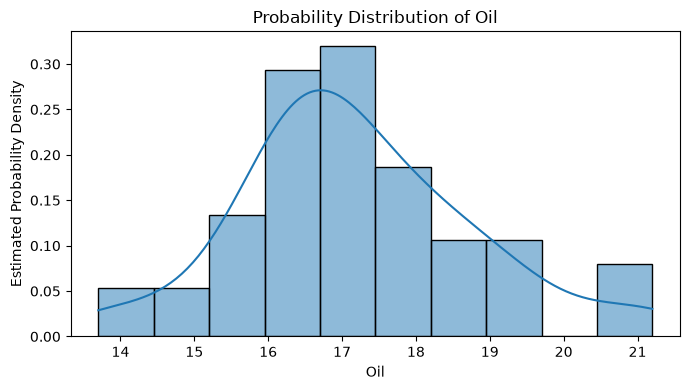

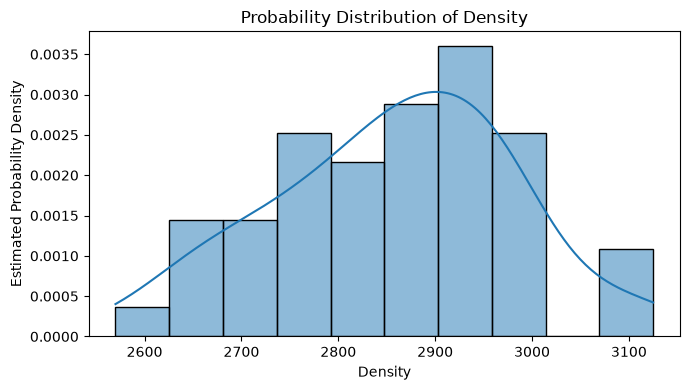

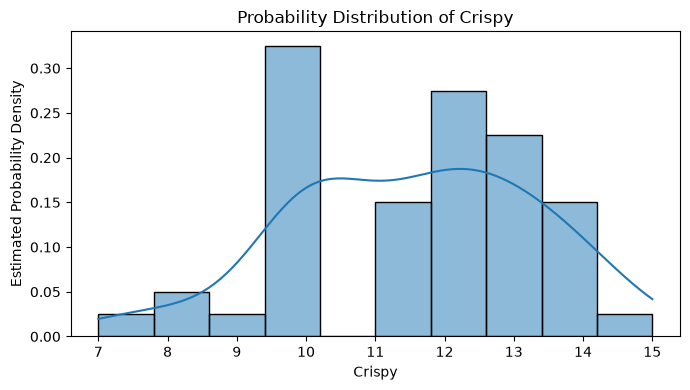

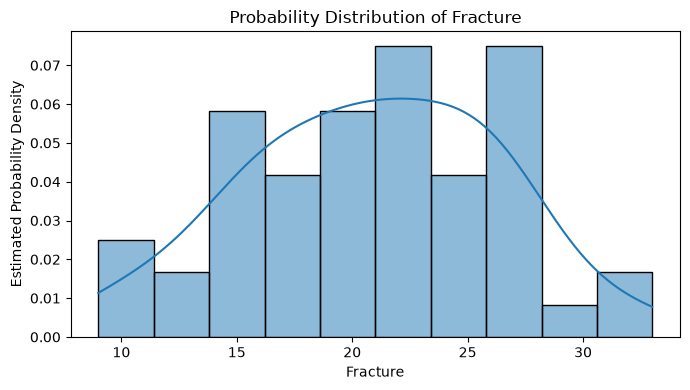

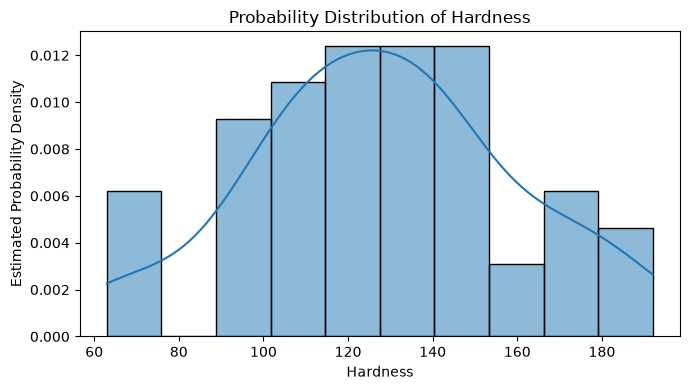

In [11]:
df = df.drop(columns=["Unnamed: 0"], errors="ignore")

features = df.select_dtypes(include="number").columns

for feature in features:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df,x=feature,bins=10,kde=True,stat="density")

    plt.title(f"Probability Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Estimated Probability Density")

    plt.tight_layout()
    plt.show()

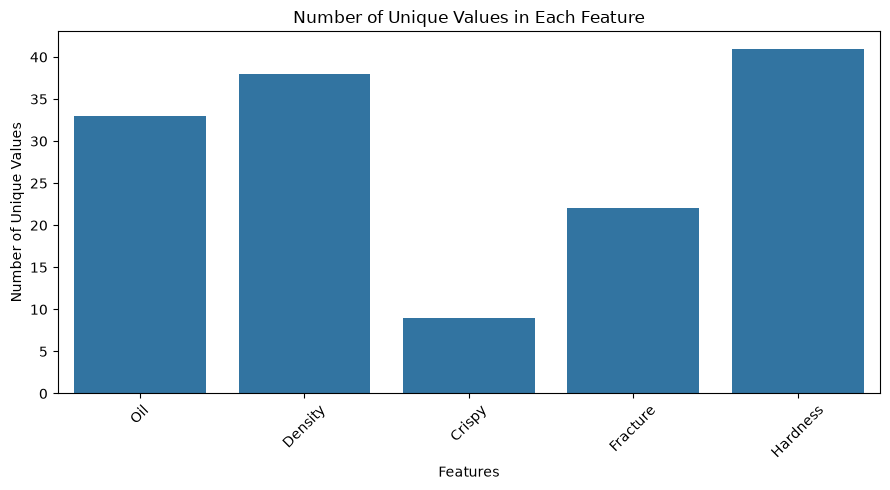

C:\Users\MSIS\AppData\Local\Temp\ipykernel_15692\2736547199.py:18: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


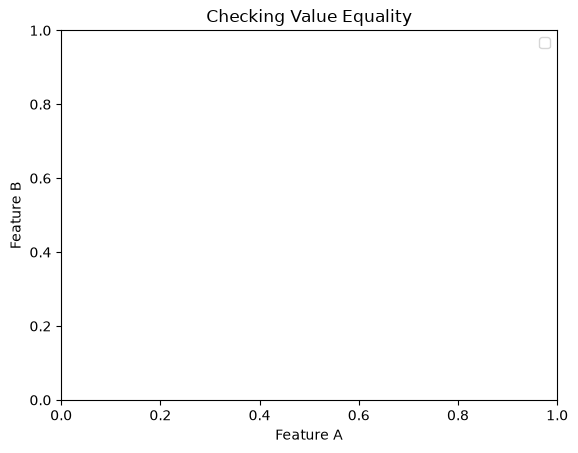

In [8]:

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

unique_counts = df.nunique()

plt.figure(figsize=(9, 5))
sns.barplot(x=unique_counts.index, y=unique_counts.values)

plt.title("Number of Unique Values in Each Feature")
plt.xlabel("Features")
plt.ylabel("Number of Unique Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.title('Checking Value Equality')
plt.xlabel('Feature A')
plt.ylabel('Feature B')
plt.legend()
plt.show()

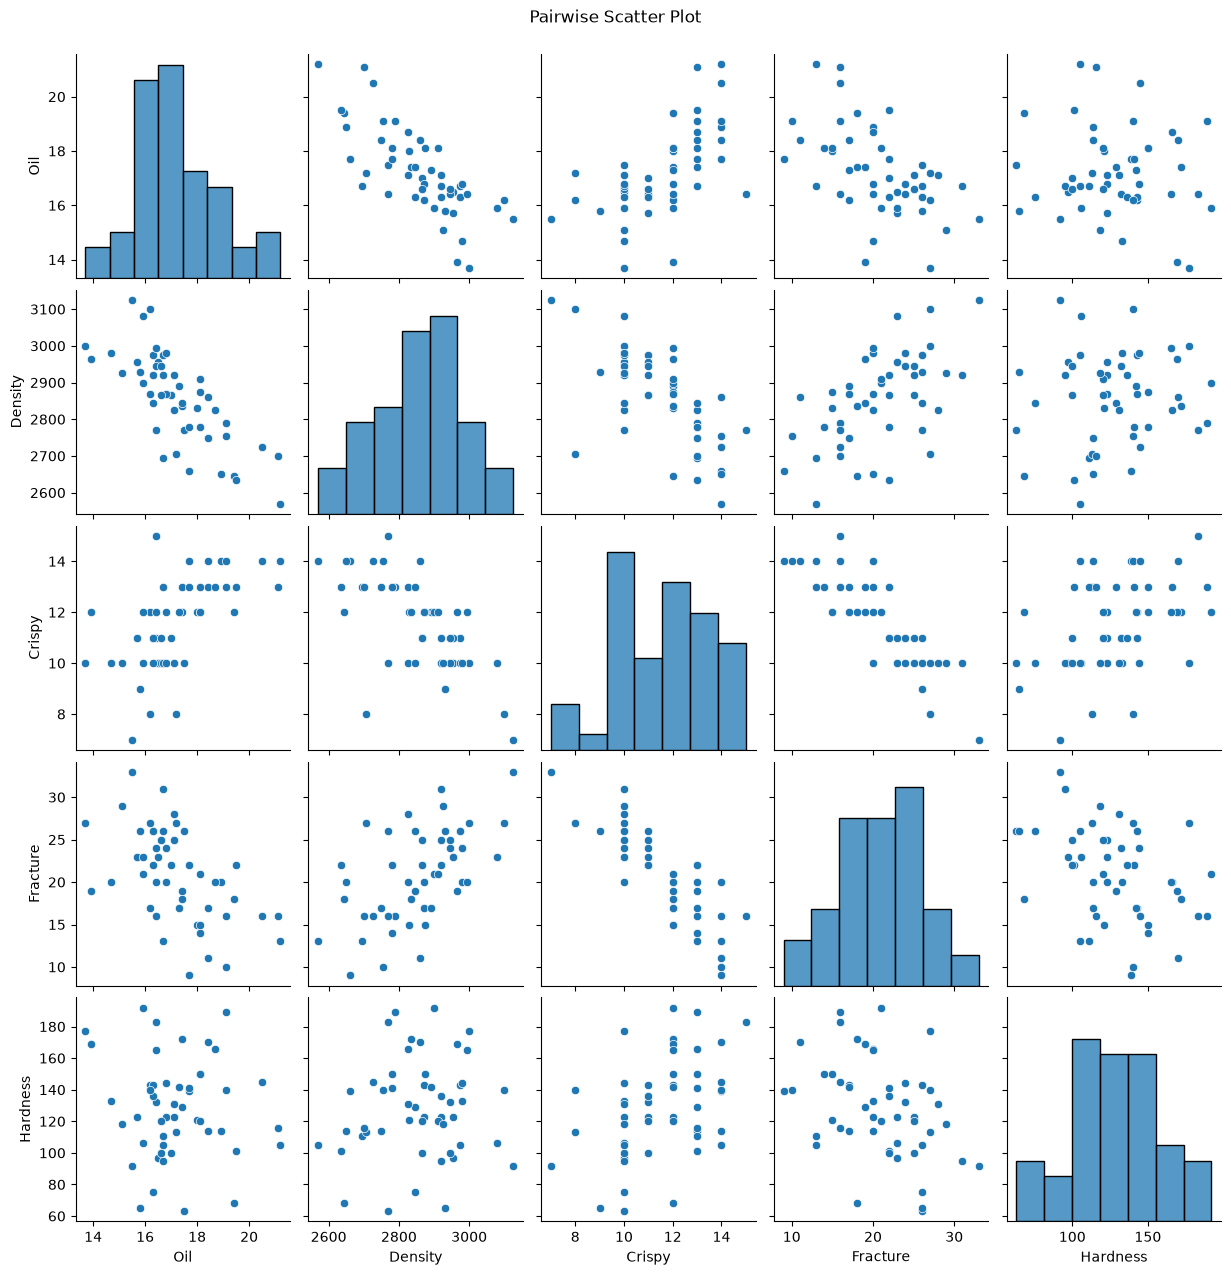

In [15]:
sns.pairplot(df, diag_kind="hist")

plt.suptitle("Pairwise Scatter Plot", y=1.02)
plt.show()

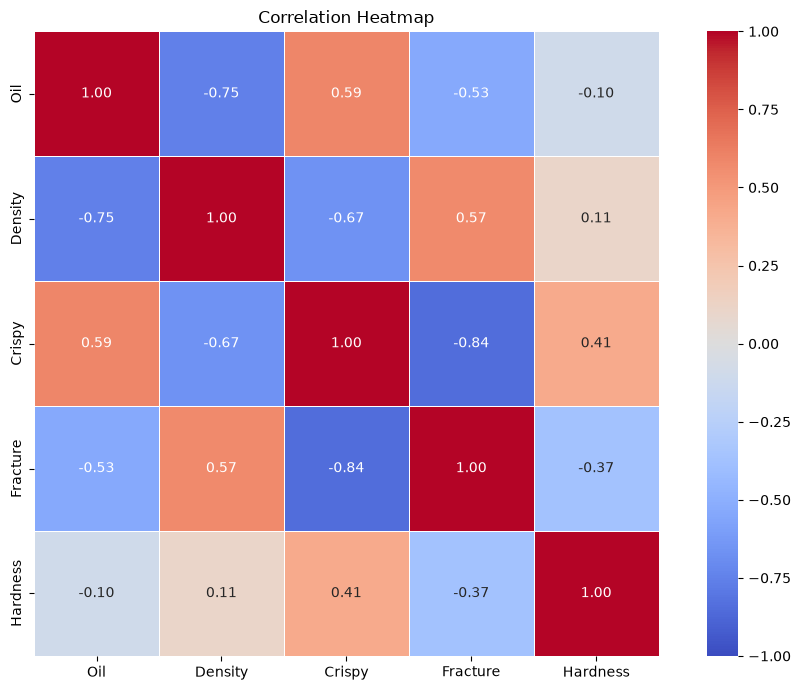

In [ ]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(10, 7))

sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f",vmin=-1,vmax=1,center=0,linewidths=0.5,square=True)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df.drop(columns=["Hardness"])
y = df["Hardness"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()

model.fit(X_train, y_train)

print("Model trained successfully!")

y_pred = model.predict(X_test)

print("\nModel Evaluation")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

results = pd.DataFrame({
    "Actual Hardness": y_test.values,
    "Predicted Hardness": y_pred
})

print("\nActual vs Predicted Values:")
print(results.to_string(index=False))

print("\nIntercept:", model.intercept_)

print("\nFeature Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient}")

Model trained successfully!

Model Evaluation
MAE: 13.567290222542772
MSE: 355.32579969457805
RMSE: 18.850087524851922
R2 Score: 0.3706592283128267

Actual vs Predicted Values:
 Actual Hardness  Predicted Hardness
             169          166.769432
             105          127.502583
             106          150.314924
             120          123.218068
             142          145.278698
             116          115.528385
             100          123.471341
             150          141.906969
              92          110.831029
             140          149.261045

Intercept: -445.20179633167936

Feature Coefficients:
Oil: -3.0164407253380157
Density: 0.17127099957792888
Crispy: 13.448407107828531
Fracture: -0.8052444447314183
